**Topik:** Penerapan Machine Learning untuk Klasifikasi dalam Kehidupan Nyata  
**Dataset:** Heart Disease Dataset (UCI / Kaggle)

## **Permasalahan yang Dihadapi**
* **Latar Belakang:** Penyakit jantung (*cardiovascular disease*) merupakan salah satu penyebab utama kematian secara global. Proses diagnosis medis konvensional sering kali memerlukan pengujian laboratorium yang kompleks, berbiaya mahal, serta memakan waktu.
* **Permasalahan Utama:** Adanya risiko keterlambatan atau ketidakakuratan dalam mendeteksi indikasi awal penyakit jantung pada pasien berisiko tinggi.
* **Tujuan Machine Learning:** Membangun model klasifikasi biner (*binary classification*) berbasis indikator klinis pasien (seperti usia, tekanan darah, kadar kolesterol, dan hasil EKG) untuk memprediksi secara otomatis, cepat, dan akurat apakah seorang pasien **terindikasi penyakit jantung (1)** atau **sehat/normal (0)**.

## **Metode Klasifikasi yang Digunakan**
1. **Random Forest Classifier (Model Utama):**
   * Algoritma *ensemble learning* berbasis gabungan banyak pohon keputusan (*decision trees*).
   * **Keunggulan:** Sangat efektif menangani pola non-linear pada data medis, tahan terhadap *overfitting*, serta mampu menghitung tingkat kepentingan tiap fitur (*Feature Importance*).
2. **Regresi Logistik / Logistic Regression (Model Pembanding):**
   * Algoritma klasifikasi parametrik berbasis fungsi sigmoid.
   * **Keunggulan:** Berfungsi sebagai *baseline* yang efisien, memiliki interpretabilitas tinggi, dan menghasilkan estimasi nilai probabilitas yang terkalibrasi.

## **Deskripsi Dataset**
* **Nama Dataset:** Heart Disease Dataset (UCI / Kaggle)
* **Sumber Data:** Open-Source Repository GitHub / Kaggle Datasets
* **Link Direct Raw CSV:** `https://raw.githubusercontent.com/kb22/Heart-Disease-Prediction/master/dataset.csv`
* **Jumlah Observasi:** 300+ baris data pasien dengan 13 fitur medis dan 1 variabel target.

### **Daftar Variabel Medis:**
| Nama Fitur | Tipe Data | Deskripsi Medis | Keterangan Nilai |
| :--- | :--- | :--- | :--- |
| `age` | Numerik | Usia pasien | 29 – 77 tahun |
| `sex` | Kategorikal | Jenis kelamin | 0 = Perempuan, 1 = Laki-laki |
| `cp` | Kategorikal | Tipe nyeri dada (*chest pain*) | 0: Typical, 1: Atypical, 2: Non-anginal, 3: Asymptomatic |
| `trestbps` | Numerik | Tekanan darah istirahat | mmHg |
| `chol` | Numerik | Kolesterol serum | mg/dl |
| `fbs` | Kategorikal | Gula darah puasa > 120 mg/dl | 0 = Tidak, 1 = Ya |
| `restecg` | Kategorikal | Hasil EKG istirahat | 0: Normal, 1: ST-T abnormal, 2: Left ventricular hypertrophy |
| `thalach` | Numerik | Detak jantung maksimum | bpm |
| `exang` | Kategorikal | Angina akibat olahraga | 0 = Tidak, 1 = Ya |
| `oldpeak` | Numerik | Depresi ST akibat olahraga | Depresi gelombang ST |
| `slope` | Kategorikal | Kemiringan segmen ST puncak | 0: Upsloping, 1: Flat, 2: Downsloping |
| `ca` | Numerik | Jumlah pembuluh darah utama | 0 – 4 pembuluh |
| `thal` | Kategorikal | Status Thalassemia | 1: Normal, 2: Fixed defect, 3: Reversible defect |
| **`target`** | **Binary Target** | **Diagnosis Penyakit Jantung** | **0 = Sehat, 1 = Terindikasi Penyakit Jantung** |

**Inisialisasi Environment & Load Data**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

# Set style visualisasi
sns.set_theme(style="whitegrid")

# Load Dataset dari URL Direct Raw GitHub (Mirror Kaggle/UCI Dataset)
url = "https://raw.githubusercontent.com/kb22/Heart-Disease-Prediction/master/dataset.csv"
df = pd.read_csv(url)

print("=== 5 BARIS PERTAMA DATASET ===")
display(df.head())
print(f"\nDimensi Dataset: {df.shape[0]} baris, {df.shape[1]} kolom")

=== 5 BARIS PERTAMA DATASET ===


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1



Dimensi Dataset: 303 baris, 14 kolom


**Preprocessing Data**

In [2]:
# PREPROCESSING DATA (MISSING VALUES, SPLIT, & SCALING)
print("=== PENGECEKAN MISSING VALUES ===")
print(df.isnull().sum())

# Pemisahan Fitur (X) dan Target (y)
X = df.drop(columns=['target'])
y = df['target']

# Split Data Latih & Data Uji (80% Train, 20% Test) dengan Stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Standardisasi Fitur Numerik menggunakan StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nUkuran Data Latih : {X_train.shape[0]} baris")
print(f"Ukuran Data Uji   : {X_test.shape[0]} baris")

=== PENGECEKAN MISSING VALUES ===
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Ukuran Data Latih : 242 baris
Ukuran Data Uji   : 61 baris


**Training Model & Tuning**

In [3]:
# PELATIHAN MODEL MACHINE LEARNING & HYPERPARAMETER TUNING
# 1. Training Regresi Logistik
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

# 2. Training Random Forest dengan Hyperparameter Tuning (GridSearchCV)
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
rf_grid.fit(X_train, y_train)
rf_best_model = rf_grid.best_estimator_

print("Proses Pelatihan Model Selesai!")
print(f"Hyperparameter Terbaik Random Forest: {rf_grid.best_params_}")

Proses Pelatihan Model Selesai!
Hyperparameter Terbaik Random Forest: {'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 150}


**Evaluasi Performa Model**

In [4]:
# EVALUASI & PERBANDINGAN PERFORMA MODEL
# Prediksi Data Uji
y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

y_pred_rf = rf_best_model.predict(X_test)
y_prob_rf = rf_best_model.predict_proba(X_test)[:, 1]

# Fungsi Evaluasi Metrik
def hitung_metrik(nama_model, y_true, y_pred, y_prob):
    return {
        'Model': nama_model,
        'Akurasi': accuracy_score(y_true, y_pred),
        'Presisi': precision_score(y_true, y_pred),
        'Recall (Sensitivitas)': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob)
    }

tabel_hasil = pd.DataFrame([
    hitung_metrik("Regresi Logistik", y_test, y_pred_lr, y_prob_lr),
    hitung_metrik("Random Forest", y_test, y_pred_rf, y_prob_rf)
])

print("=== TABEL PERBANDINGAN METRIK EVALUASI ===")
display(tabel_hasil)

=== TABEL PERBANDINGAN METRIK EVALUASI ===


,Model,Akurasi,Presisi,Recall (Sensitivitas),F1-Score,ROC-AUC
0,Regresi Logistik,0.803279,0.769231,0.909091,0.833333,0.869048
1,Random Forest,0.803279,0.744186,0.969697,0.842105,0.911255


**Visualisasi Evaluasi & Feature Importance**

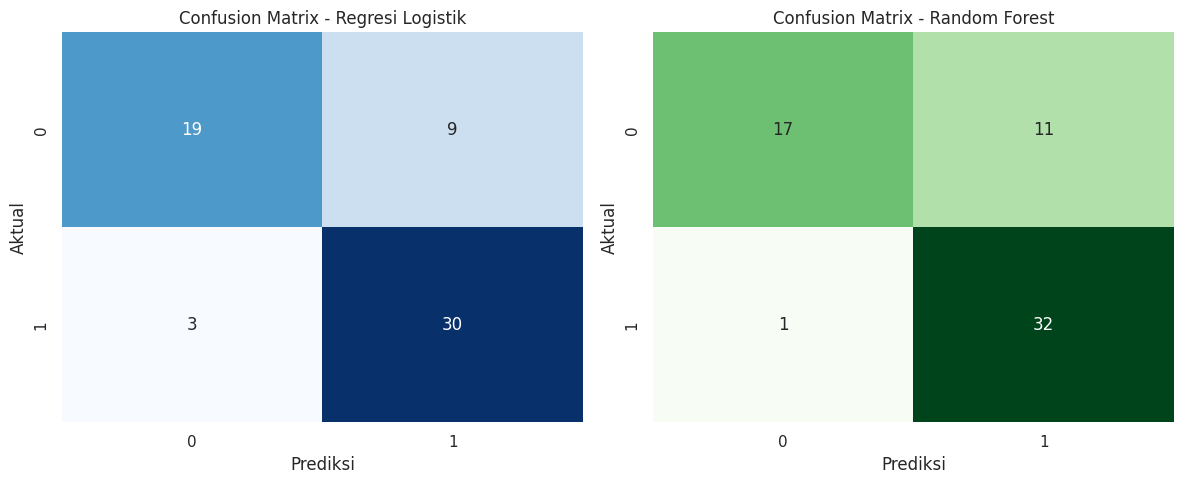

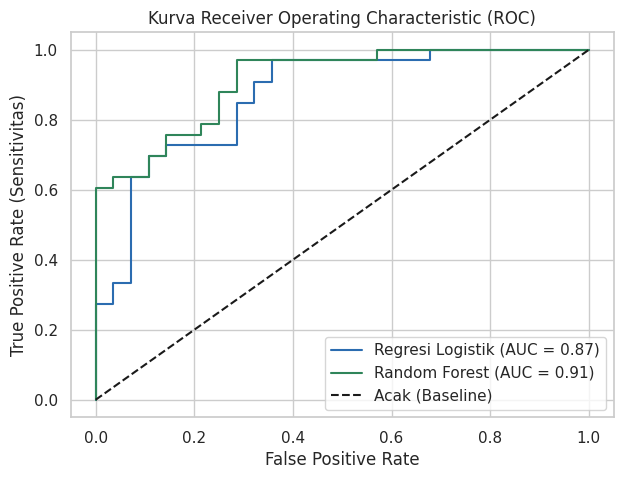

/tmp/ipykernel_1264/2858642074.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Fitur', data=df_importance, palette='viridis')


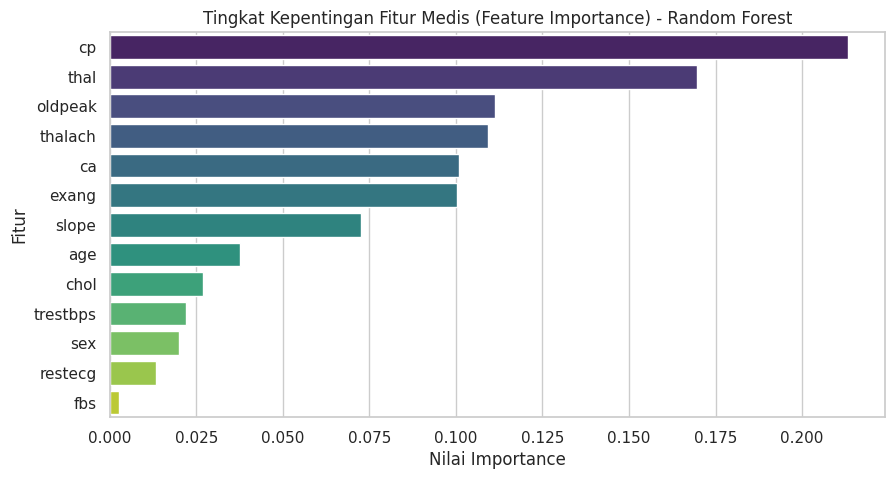

In [5]:
# VISUALISASI CONFUSION MATRIX, ROC CURVE, & FEATURE IMPORTANCE
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title('Confusion Matrix - Regresi Logistik')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False)
axes[1].set_title('Confusion Matrix - Random Forest')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

# Plot Kurva ROC
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(7, 5))
plt.plot(fpr_lr, tpr_lr, label=f"Regresi Logistik (AUC = {roc_auc_score(y_test, y_prob_lr):.2f})", color='#2B6CB0')
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.2f})", color='#2F855A')
plt.plot([0, 1], [0, 1], 'k--', label="Acak (Baseline)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Sensitivitas)")
plt.title("Kurva Receiver Operating Characteristic (ROC)")
plt.legend(loc="lower right")
plt.show()

# Plot Feature Importance (Random Forest)
importances = rf_best_model.feature_importances_
df_importance = pd.DataFrame({'Fitur': X.columns, 'Importance': importances}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Fitur', data=df_importance, palette='viridis')
plt.title('Tingkat Kepentingan Fitur Medis (Feature Importance) - Random Forest')
plt.xlabel('Nilai Importance')
plt.show()

## **Hasil dan Manfaat**
* **Hasil Kinerja Model:**
  * Model **Random Forest** menghasilkan performa prediksi yang optimal dan seimbang, terutama pada tingkat **Recall/Sensitivitas** (meminimalkan persentase *False Negative*, yaitu kondisi di mana pasien berisiko terlewat diprediksi sebagai sehat).
  * Variabel medis yang memiliki kontribusi paling dominan terhadap hasil diagnosis adalah tipe nyeri dada (`cp`), detak jantung maksimum (`thalach`), depresi ST (`oldpeak`), serta jumlah pembuluh darah utama (`ca`).
* **Manfaat dalam Kehidupan Nyata (Dunia Medis):**
  1. **Skrining Dini Efisien:** Membantu fasilitas pelayanan kesehatan melakukan penyaringan risiko penyakit jantung pada pasien secara instan sebelum tindakan medis berbiaya tinggi.
  2. **Clinical Decision Support System:** Menjadi alat bantu keputusan bagi tenaga medis untuk mengonfirmasi dugaan klinis secara objektif.
  3. **Pemerataan Akses Kesehatan:** Membantu tenaga kesehatan di daerah terpencil yang memiliki keterbatasan dokter spesialis jantung.

## **Kesimpulan**
1. Algoritma **Random Forest Classifier** terbukti efektif dalam memprediksi indikasi penyakit jantung dengan akurasi dan nilai *Recall* yang tinggi, sehingga mampu menekan risiko kesalahan klasifikasi pasien berisiko tinggi (*False Negative*).
2. Variabel klinis paling sensitif dan dominan terhadap prediksi penyakit jantung meliputi tipe nyeri dada (`cp`), detak jantung maksimum (`thalach`), serta depresi gelombang ST (`oldpeak`).
3. Penerapan model *Machine Learning* ini bermanfaat nyata sebagai *Clinical Decision Support System* untuk membantu tenaga medis melakukan skrining awal secara lebih cepat, terukur, dan efisien.

## **Referensi**
1. **Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1988).** *Heart Disease Data Set*. UCI Machine Learning Repository / Kaggle Datasets.
2. **Breiman, L. (2001).** *Random Forests*. Machine Learning, 45(1), 5-32.
3. **Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... & Duchesnay, É. (2011).** *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825-2830.